**Step 1: Import Libraries & Load Dataset**

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats

# Set visualization style
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv('/content/hour.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


**Step 2. Initial data inspection**

In [2]:
# Dataset shape
print("Dataset Shape:", df.shape)

# First 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# Last 5 rows
print("\nLast 5 Rows:")
display(df.tail())

# Dataset information
print("\nDataset Information:")
df.info()

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (17379, 17)

First 5 Rows:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1



Last 5 Rows:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61
17378,17379,2012-12-31,1,1,12,23,0,1,1,1,0.26,0.2727,0.65,0.1343,12,37,49



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Column Names:
['instant', 

**Step 3. Summary statistics**

In [3]:
# Numerical summary
print("Numerical Summary:")
display(df.describe())

# Complete summary including categorical data
print("\nComplete Summary:")
display(df.describe(include='all'))

# Unique values in categorical columns
categorical_cols = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit'
]

for col in categorical_cols:
    print(f"\n{col} - Unique Values:")
    print(df[col].unique())

Numerical Summary:


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



Complete Summary:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
unique,NaN,731,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,2012-12-31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,8690.0000,NaN,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,NaN,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,NaN,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,NaN,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,NaN,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000



season - Unique Values:
[1 2 3 4]

yr - Unique Values:
[0 1]

mnth - Unique Values:
[ 1  2  3  4  5  6  7  8  9 10 11 12]

hr - Unique Values:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23]

holiday - Unique Values:
[0 1]

weekday - Unique Values:
[6 0 1 2 3 4 5]

workingday - Unique Values:
[0 1]

weathersit - Unique Values:
[1 2 3 4]


**Step 4: Data Cleaning & Preprocessing**

In [4]:
# Create a copy of the dataset
df = df.copy()

# Convert date column into datetime format
df['dteday'] = pd.to_datetime(df['dteday'])

# Convert categorical columns into category datatype
category_cols = [
    'season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit'
]

for col in category_cols:
    df[col] = df[col].astype('category')

# Replace season codes with season names
df['season_name'] = df['season'].map({
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
})

# Replace weather codes with weather names
df['weather_name'] = df['weathersit'].map({
    1: 'Clear',
    2: 'Mist/Cloudy',
    3: 'Light Rain/Snow',
    4: 'Heavy Rain/Snow'
})

# Check updated dataset
print("Updated Dataset:")
display(df.head())

# Check updated data types
print("\nUpdated Data Types:")
print(df.dtypes)

# Final missing value check
print("\nMissing Values:")
print(df.isnull().sum())

Updated Dataset:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_name,weather_name
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Spring,Clear
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Spring,Clear
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Spring,Clear
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Spring,Clear
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Spring,Clear



Updated Data Types:
instant                  int64
dteday          datetime64[ns]
season                category
yr                    category
mnth                  category
hr                    category
holiday               category
weekday               category
workingday            category
weathersit            category
temp                   float64
atemp                  float64
hum                    float64
windspeed              float64
casual                   int64
registered               int64
cnt                      int64
season_name           category
weather_name          category
dtype: object

Missing Values:
instant         0
dteday          0
season          0
yr              0
mnth            0
hr              0
holiday         0
weekday         0
workingday      0
weathersit      0
temp            0
atemp           0
hum             0
windspeed       0
casual          0
registered      0
cnt             0
season_name     0
weather_name    0
dtype: int64


**Step 5: Distribution Analysis**

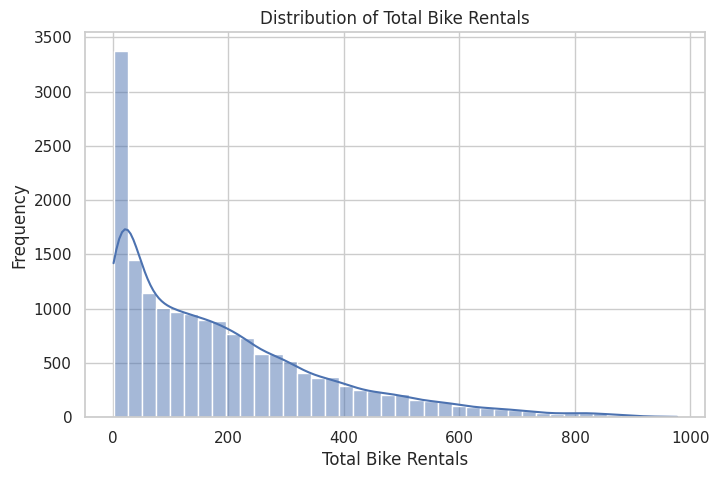

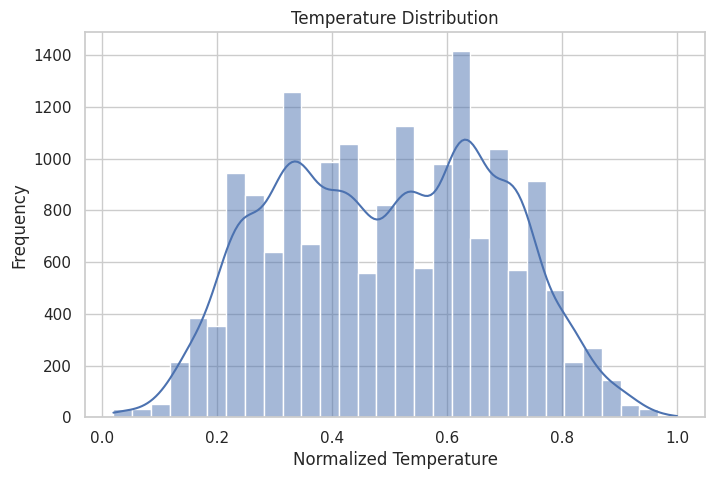

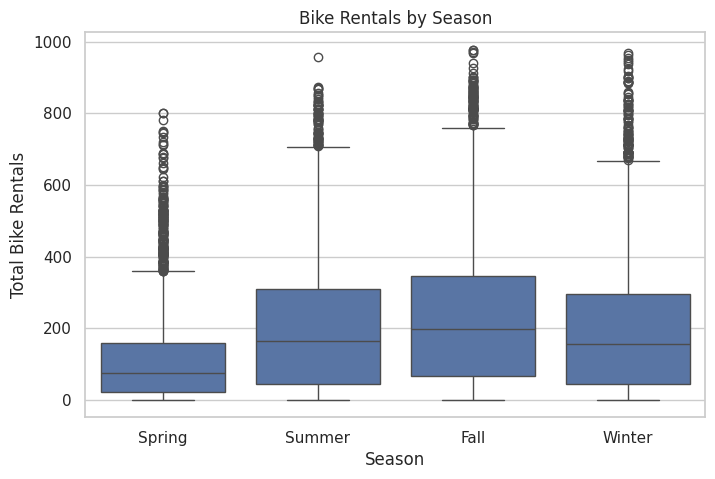

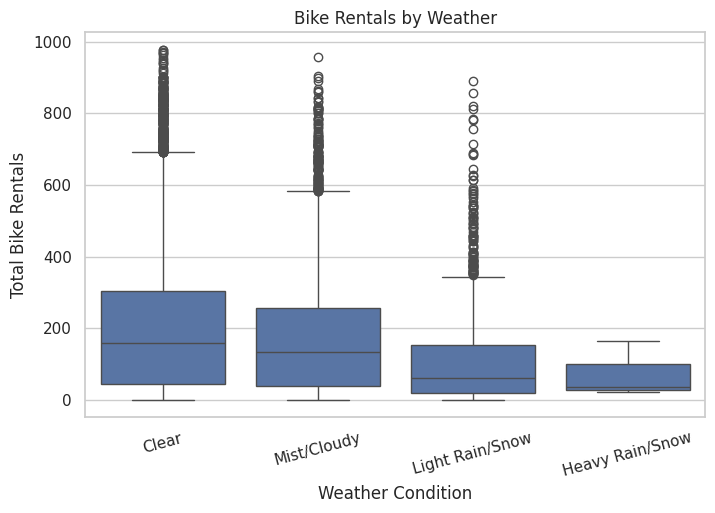

In [5]:
# 1. Distribution of Total Bike Rentals

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='cnt', bins=40, kde=True)
plt.title('Distribution of Total Bike Rentals')
plt.xlabel('Total Bike Rentals')
plt.ylabel('Frequency')
plt.show()


# 2. Distribution of Temperature

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='temp', bins=30, kde=True)
plt.title('Temperature Distribution')
plt.xlabel('Normalized Temperature')
plt.ylabel('Frequency')
plt.show()


# 3. Bike Rentals by Season

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='season_name', y='cnt')
plt.title('Bike Rentals by Season')
plt.xlabel('Season')
plt.ylabel('Total Bike Rentals')
plt.show()


# 4. Bike Rentals by Weather

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='weather_name', y='cnt')
plt.title('Bike Rentals by Weather')
plt.xlabel('Weather Condition')
plt.ylabel('Total Bike Rentals')
plt.xticks(rotation=15)
plt.show()

**Step 6: Correlation & Relationship Analysis**

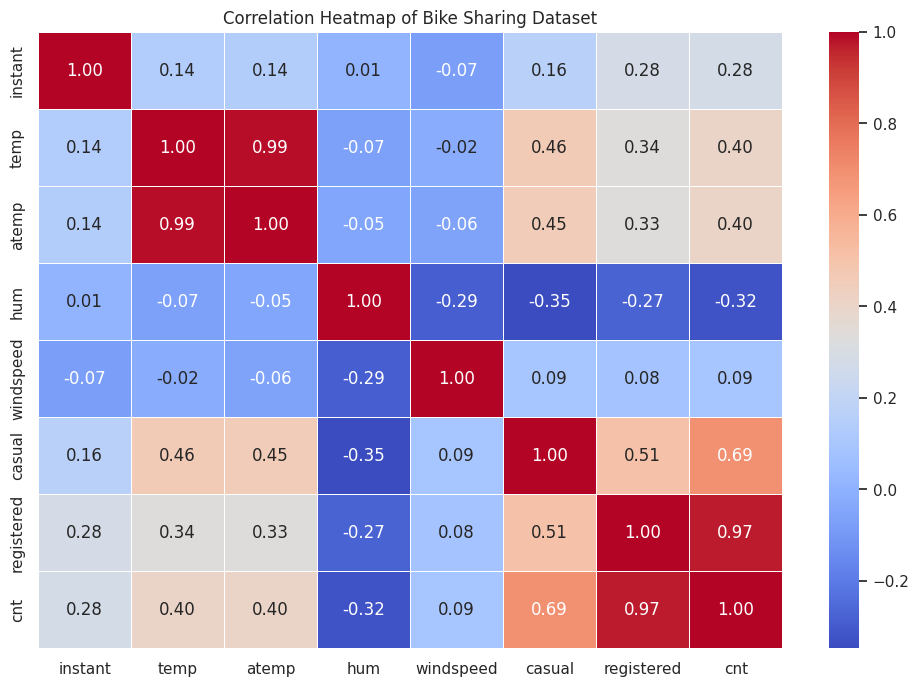

Pearson Correlation with Bike Rentals:
cnt           1.000000
registered    0.972151
casual        0.694564
temp          0.404772
atemp         0.400929
instant       0.278379
windspeed     0.093234
hum          -0.322911
Name: cnt, dtype: float64

Spearman Correlation with Bike Rentals:
cnt           1.000000
registered    0.989444
casual        0.850525
temp          0.423330
atemp         0.423258
instant       0.243742
windspeed     0.126629
hum          -0.359614
Name: cnt, dtype: float64


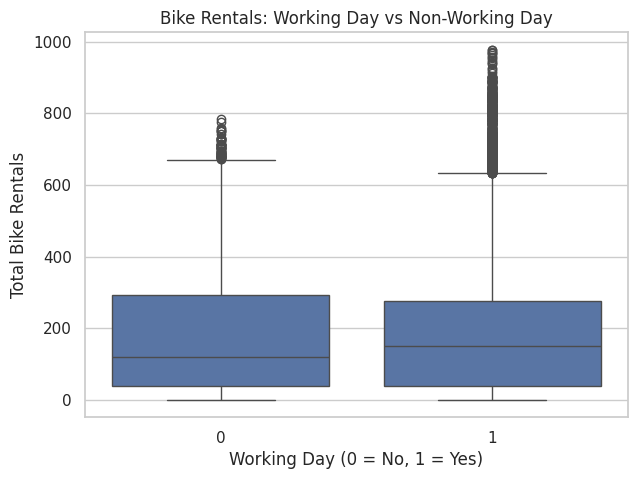

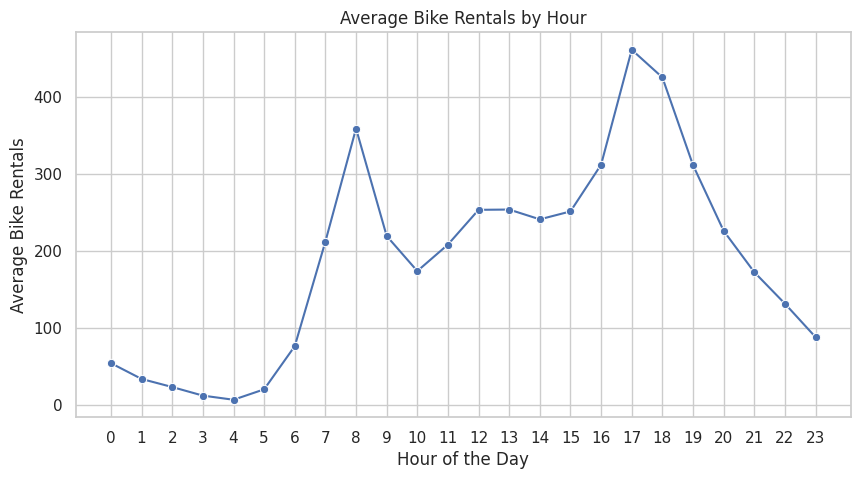

In [6]:
# 1. Correlation Matrix

numeric_df = df.select_dtypes(include=['number'])

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Bike Sharing Dataset')
plt.show()


# 2. Pearson and Spearman Correlation with Bike Rentals

print("Pearson Correlation with Bike Rentals:")
print(numeric_df.corr(method='pearson')['cnt'].sort_values(ascending=False))

print("\nSpearman Correlation with Bike Rentals:")
print(numeric_df.corr(method='spearman')['cnt'].sort_values(ascending=False))


# 3. Bike Rentals by Working Day

plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x='workingday', y='cnt')

plt.title('Bike Rentals: Working Day vs Non-Working Day')
plt.xlabel('Working Day (0 = No, 1 = Yes)')
plt.ylabel('Total Bike Rentals')
plt.show()


# 4. Average Bike Rentals by Hour

hourly_rentals = df.groupby('hr', observed=True)['cnt'].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(x=hourly_rentals.index.astype(int),
             y=hourly_rentals.values,
             marker='o')

plt.title('Average Bike Rentals by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rentals')
plt.xticks(range(24))
plt.show()

**Step 7: Skewness and Kurtosis**

In [7]:
# Skewness and Kurtosis Analysis

numeric_cols = [
    'temp', 'atemp', 'hum', 'windspeed',
    'casual', 'registered', 'cnt'
]

# Calculate Skewness
skewness = df[numeric_cols].skew()

# Calculate Kurtosis
kurtosis = df[numeric_cols].kurtosis()

# Display Results
distribution_analysis = pd.DataFrame({
    'Skewness': skewness,
    'Kurtosis': kurtosis
})

print("Skewness and Kurtosis Analysis:\n")
print(distribution_analysis.round(3))

Skewness and Kurtosis Analysis:

            Skewness  Kurtosis
temp          -0.006    -0.942
atemp         -0.090    -0.845
hum           -0.111    -0.826
windspeed      0.575     0.591
casual         2.499     7.571
registered     1.558     2.750
cnt            1.277     1.417


**Step 8: Outlier Detection (IQR + Z-Score**)

In [8]:
from scipy import stats
import numpy as np

# Outlier Detection on Total Bike Rentals
Q1 = df['cnt'].quantile(0.25)
Q3 = df['cnt'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# IQR Outliers
iqr_outliers = df[
    (df['cnt'] < lower_limit) |
    (df['cnt'] > upper_limit)
]

# Z-Score Method
z_scores = np.abs(stats.zscore(df['cnt']))
z_outliers = df[z_scores > 3]

print("IQR Method")
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(iqr_outliers))

print("\nZ-Score Method")
print("Number of Outliers:", len(z_outliers))

IQR Method
Lower Limit: -321.5
Upper Limit: 642.5
Number of Outliers: 505

Z-Score Method
Number of Outliers: 244


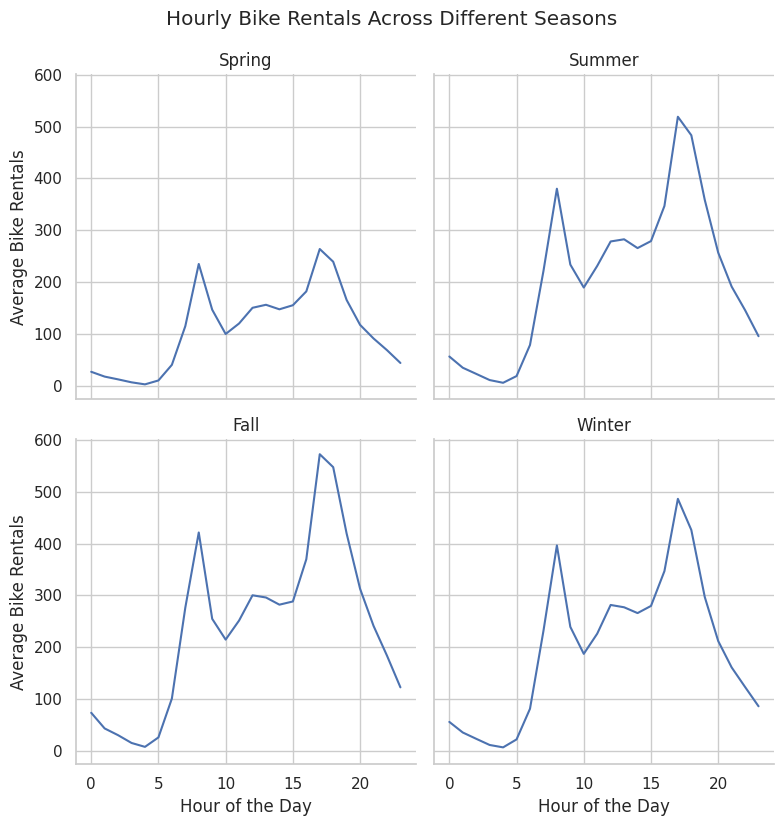

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.FacetGrid(
    df,
    col="season_name",
    col_wrap=2,
    height=4
)

g.map_dataframe(
    sns.lineplot,
    x="hr",
    y="cnt",
    estimator="mean",
    errorbar=None
)

g.set_axis_labels("Hour of the Day", "Average Bike Rentals")
g.set_titles("{col_name}")
g.fig.suptitle("Hourly Bike Rentals Across Different Seasons", y=1.03)

plt.show()

**Step: Pairplot Visualization**

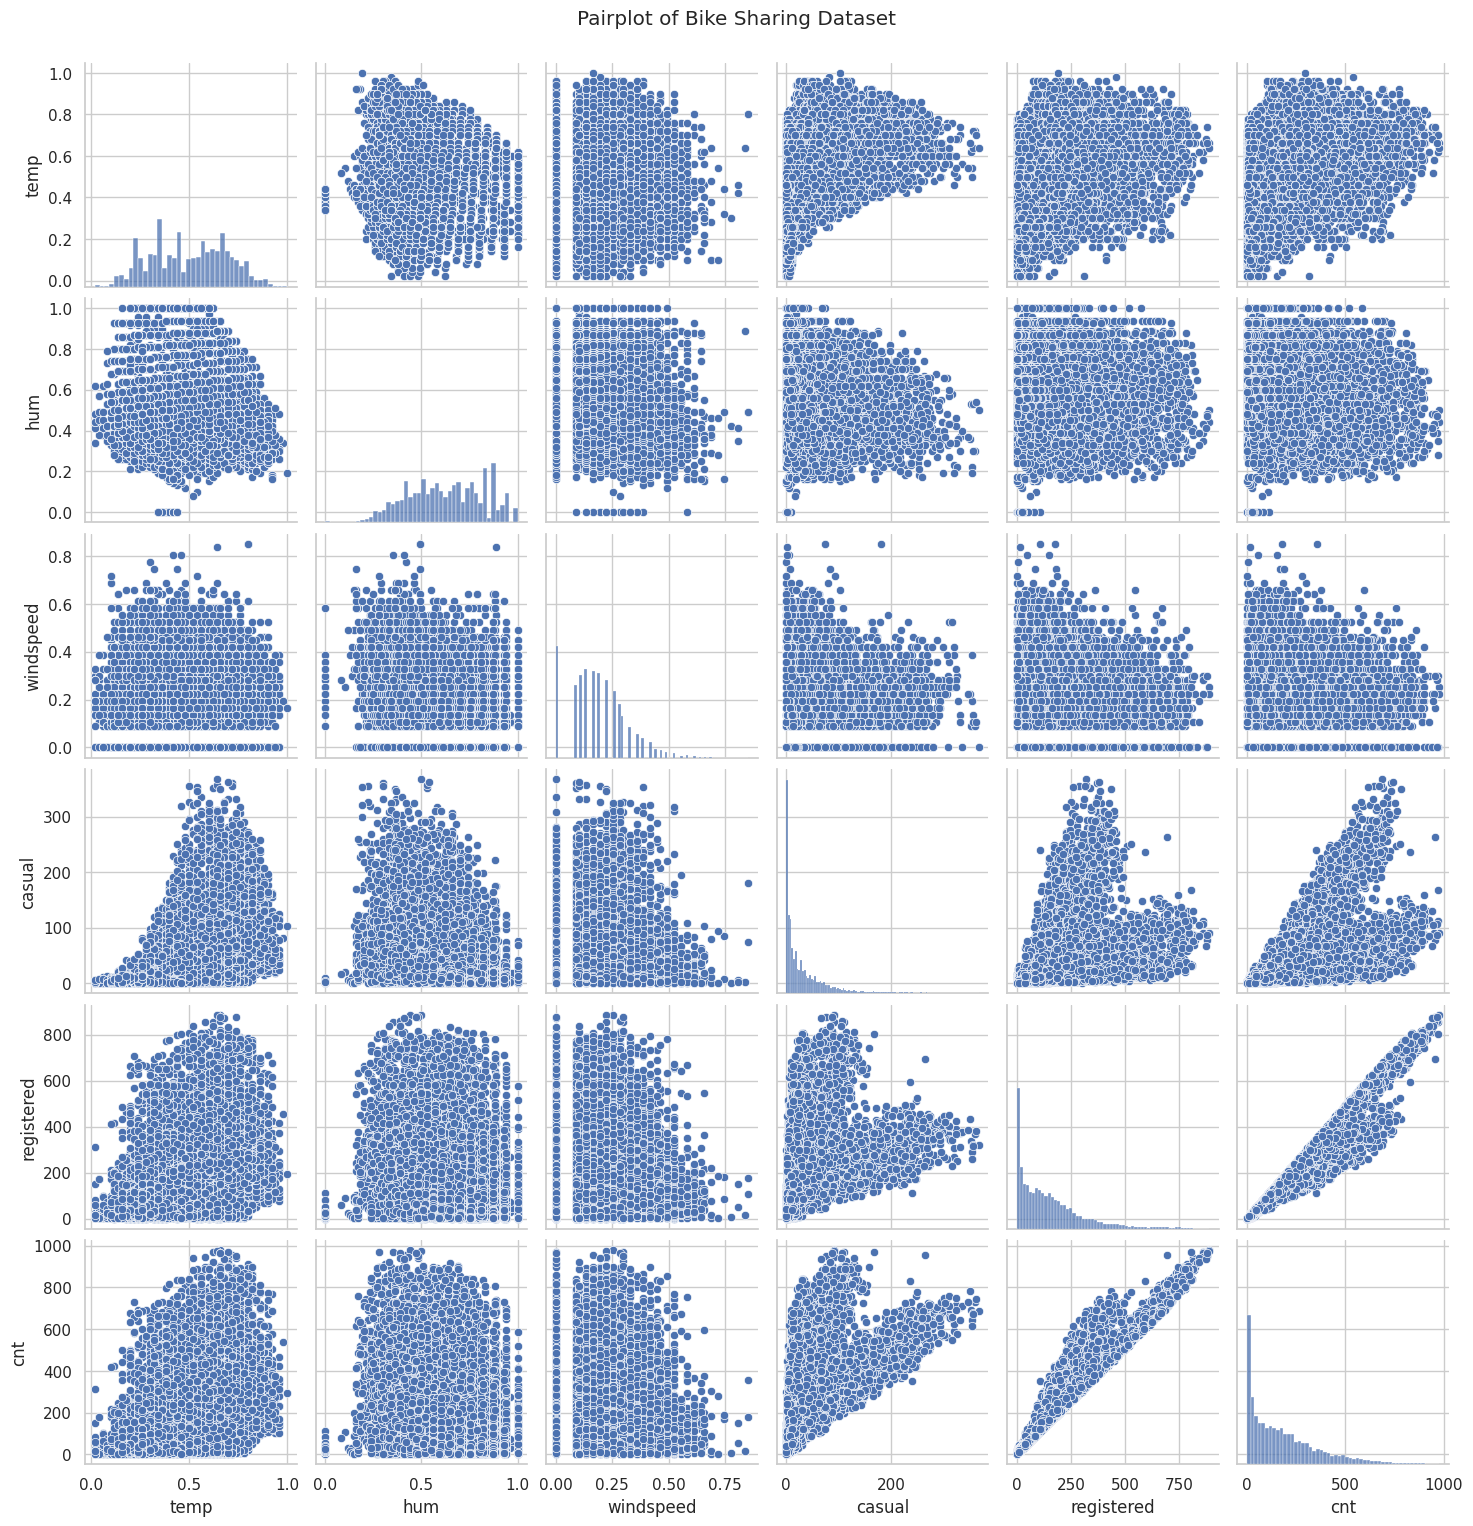

In [10]:
sns.pairplot(
    df[['temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']],
    diag_kind='hist'
)

plt.suptitle("Pairplot of Bike Sharing Dataset", y=1.02)
plt.show()